<a href="https://colab.research.google.com/github/kimve1969/msu_ds_pinn_2d_heat/blob/3-%D1%80%D0%B0%D0%B7%D1%80%D0%B0%D0%B1%D0%BE%D1%82%D0%BE%D1%82%D0%B0%D1%82%D1%8C-pinn-%D0%BC%D0%BE%D0%B4%D0%B5%D0%BB%D1%8C-%D1%82%D0%B5%D0%BF%D0%BB%D0%BE%D0%BF%D1%80%D0%BE%D0%B2%D0%BE%D0%B4%D0%BD%D0%BE%D1%81%D1%82%D0%B8/msu-pinn-2d-heat.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Аттестационная работа по DS & ML
#### МГУ, декабрь 2026, В.Е.Ким


## Постановка задачи:

Применение нейронной сети для решения обратной задачи физики процесса (PINN), описываемого дифференциальным уравнением, на примере нестационарного 2D уравнения теплопроводности (УТ) и его сравнение с численным методом МКР (метод конечной разности), взятым за эталон решения.

## Планируемое решение задачи:

1. Решение прямой задачи УТ с применением МКР неявным методом на 2D сетке с заданными граничными и начальными условиями Дирихле. Коэффициент теплопроводности задается матрицей в каждом узлу сетки (при расчете вычисляется гармонические коэффиценты теплопроводности между всеми узлами сетки). Исходная матрица коэффициентов теплопроводности является искомой для последующего решения в обратной задаче с применением PINN.
2. Решение прямой задачи УТ с применением PINN.  

# ШАГ 1
## Прямая задача решения 2D нестационарного уравнения теплопроводности методом конечной разности (МКР), неявная схема

Уравнение:
$$
\frac{\partial u}{\partial t} = \alpha(\frac{\partial^2 u}{\partial x^2} + \frac{\partial^2 u}{\partial y^2})
$$

Для решения диф. ур-ия, применим неявную схему (Backward Euler): \
$$ \frac{u_{i,j}^{n+1} - u_{i,j}^n}{\Delta t} = \alpha(A_x u_{i,j}^{n+1} + A_y u_{i,j}^{n+1}) $$
где: $ A_x, A_y $ - дискретные операторы Лапласа по направлениям: $ A_x u_{i,j} = \frac{u_{i-1,j} - 2u_{i,j} + u_{i+1,j}}{\Delta x^2} $, $ A_y u_{i,j} = \frac{u_{i,j-1} - 2u_{i,j} + u_{i,j+1}}{\Delta y^2} $

что приводит к СЛАУ:
$$ (I - \Delta t \cdot α \cdot A) u^{n+1} = u^n $$
где: I - единичный оператор (не единичная диагональная матрица!), A - дискретный оператор Лапласа (5-точечный шаблон)
для функции $u_{i,j}$ в узле сетки (i,j),
если $(Δx=Δy=h)$, то:
$
Au_{i,j}\approx \frac{u_{i-1,j}+u_{i+1,j}+u_{i,j-1}+u_{i,j+1}-4u_{i,j}}{h^2}
$
и шаблона оператора А выглядит так:
$$
A = \frac{1}{h^2}
\begin{bmatrix}
& 1 & \\
1 & -4 & 1\\
& 1 &
\end{bmatrix}
$$
если $ Δx \ne Δy $, то: $ Au_{i,j} ≈ \frac{u_{i-1,j} - 2u_{i,j} + u_{i+1,j}}{\Delta_x^2} + \frac{u_{i,j-1} - 2u_{i,j} + u_{i,j+1}}{\Delta_y^2} $ и шаблон опреатора А выглядит немного сложнее:
$$
A =
\begin{bmatrix}
& \frac{1}{Δy^2} & \\
\frac{1}{Δx^2} & -(\frac{2}{Δx^2} + \frac{2}{Δy^2}) & \frac{1}{Δx^2}\\
& \frac{1}{Δy^2} &
\end{bmatrix}
$$

Тогда оператор $M = (I - \Delta t \cdot α \cdot A)$ выглядит так:

$$
M = \Delta t \cdot α
\begin{bmatrix}
& -\frac{1}{Δy^2} & \\
-\frac{1}{Δx^2} & 1+(\frac{2}{Δx^2} + \frac{2}{Δy^2}) & -\frac{1}{Δx^2}\\
& -\frac{1}{Δy^2} &
\end{bmatrix}
$$


Ключевые моменты реализации

1. Разреженная матрица M = I - dt*A строится один раз (она не меняется со временем).
2. LU-разложение через scipy.sparse.linalg.splu — вычисляется один раз, а затем на каждом шаге делается только обратная подстановка (очень быстро).
3. Индексация: узлы $(i,j)$, $i=1\ldots N_x$, $j=1\ldots N_y$ укладываются в вектор длины $N_xN_y$.
4. Граничные условия Дирихле учитываются неявно — они не входят в вектор неизвестных, а нулевые значения на границе дают нулевой вклад в правую часть.

Устойчивость: абсолютная \
Порядок по времени: $ O(\Delta t)$ \
Порядок по пространству: $O(\Delta x^2, \Delta y^2)$ \
Стоимость шага: $O(N_x N_y)$

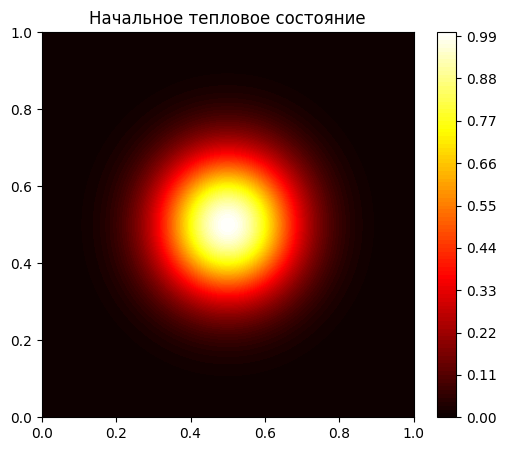

In [1]:
from numpy._core.numerictypes import float64
import numpy as np
import scipy.sparse as sp
import scipy.sparse.linalg as spla
import time
import matplotlib.pyplot as plt

# ================================================================
# ОБЩИЕ ПАРАМЕТРЫ
# ================================================================
Lx, Ly, T_final = 1.0, 1.0, 1.0

# Сетка по x, y
Nx, Ny = 100, 100
dx = Lx / (Nx - 1)
dy = Ly / (Ny - 1)

x = np.linspace(0, Lx, Nx)
y = np.linspace(0, Ly, Ny)
X, Y = np.meshgrid(x, y, indexing='ij')

# Для неявной схемы ограничение на dt отсутствует, задаём из соображений точности
Nt = 100
t = np.linspace(0, T_final, Nt)
dt = T_final / (Nt-1)

# ============ Начальное условие (типа колокол) ============
u = np.exp(-30 * ((X - 0.5)**2 + (Y - 0.5)**2))
#u = np.zeros((Nx,Ny), dtype=float64)
# ============ Граничные условия (нулевые - холодные стенки) ============
def apply_bc(u):
    # левый-верхний угол  # вверх             # правый-верхний угол
    u[0, -1] = 0.0;       u[1:-1, -1] = 0.0;  u[-1, -1] = 0.0;
    # левая сторона                           # правая сторона
    u[0, 1:-1] = 0.0;                         u[-1, 1:-1] = 0.0;
    # левый-нижний угол   # низ               # правый-нижний угол
    u[0, 0] = 0.0;        u[1:-1, 0] = 0.0;   u[-1, 0] = 0.0
    return u

u = apply_bc(u)

# ============ Функция построения тепловой 2D-карты =====================
def heat_plot(x_grid: np.ndarray, y_grid: np.ndarray, u_grid: np.ndarray, stitle: str):
  fig, ax = plt.subplots(figsize=(6, 5))
  #c = ax.contourf(x_grid, y_grid, u_grid, levels=100, cmap="hot", vmin=u_grid.min(), vmax=u_grid.max())
  c = ax.contourf(x_grid, y_grid, u_grid, levels=100, cmap="hot", vmin=0, vmax=1.0)
  plt.colorbar(c, ax=ax)
  plt.title(stitle)
  plt.show()

# ============ Визуализируем начальное состояние ========================
heat_plot(x_grid=X, y_grid=Y, u_grid=u, stitle="Начальное тепловое состояние")

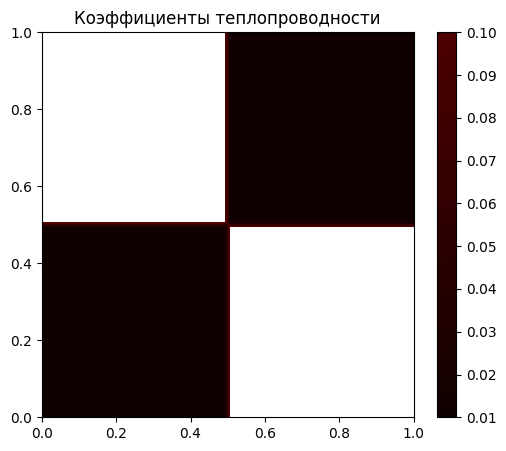

In [2]:
# Формируем матрицу коэффициентов теплопроводности
# ============================================================
# 2. Четыре области-квадрата 2x2 со своими alhpa
#    (границы раздела: x=0.5 и y=0.5)
# ============================================================
alpha = np.zeros((Nx, Ny))
alpha[(X <  0.5) & (Y <  0.5)] = 0.01     # левый-нижний
alpha[(X >= 0.5) & (Y <  0.5)] = 0.1    # правый-нижний
alpha[(X <  0.5) & (Y >= 0.5)] = 0.1   # левый-верхний
alpha[(X >= 0.5) & (Y >= 0.5)] = 0.01     # правый-верхний

np.random.seed(42)
#alpha = np.random.rand(Nx, Ny)/3.0
# ============================================================
# 3. Эффективная alpha на гранях — гармоническое среднее
# ============================================================
alpha_x_eff = 2*alpha[:-1,:]*alpha[1:,:]/(alpha[:-1,:]+alpha[1:,:])   # (Nx-1, Ny)
alpha_y_eff = 2*alpha[:,:-1]*alpha[:,1:]/(alpha[:,:-1]+alpha[:,1:])   # (Nx, Ny-1)

# ============ Визуализируем коэффициентов теплопроводности ==============
heat_plot(x_grid=X, y_grid=Y, u_grid=alpha, stitle="Коэффициенты теплопроводности")

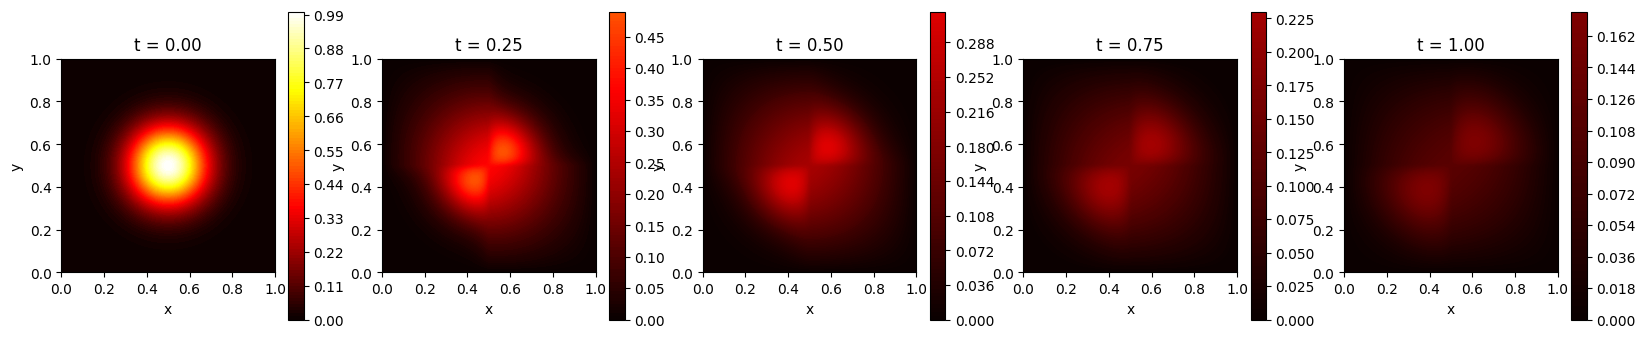

In [3]:
# Упорядочим неизвестные построчно: индекс k = i*Ny + j
# (i = 1..Nx-2, j = 1..Ny-2 - внутренние узлы)

ax_coef = alpha_x_eff * dt / dx**2
ay_coef = alpha_y_eff * dt / dy**2

# Разреженную матрицы системы M = I - dt*A будем представлять в виде 3-х векторов
rows, cols, data = [], [], []

# ================================================================
# НУМЕРАЦИЯ ВСЕХ УЗЛОВ (внутренних + граничных)
# ================================================================
def idx(i, j):
    """
    Линейный индекс idx для векторов rows, cols, data
    рассчитанный по индексам внутреннего узла M(i,j), i=0..Nx-1, j=0..Ny-1
    """
    return i * Ny + j

# упаковываем в три вектора согласно оператору M = I - dt*A (см.выше)
# узлы внутренней области: (1:Nx-2) x (1:Ny-2)
for i in range(Nx):
    for j in range(Ny):
        k = idx(i, j)

        if i==0 or i==(Nx-1) or j==0 or j==(Ny-1):
            # граничная строка: 1·u_k = g_k
            rows.append(k);
            cols.append(k);
            data.append(1.0)
            continue
        # внутренние узлы

        # alpha_x_eff[i,j] размерностью (Nx-1,Ny) эффективная \alhpa
        # между гранями (i,j) и (i+1,j), т.е. движемся вправо, узлов Nx,
        # граней Nx, аналогично
        # alpha_y_eff[i,j] размерностью (Nx, Ny-1) эффективная \alpha
        # между гранями (i,j) и (i,j+1), т.е. движемся вверх
        #
        # Для внутреннего узла (i,j) нужны 2 грани по х:
        # (i-1,j)-(i,j) и (i,j)-(i+1,j), т.е. alpha_x_eff[i-1,j] и alpha_x_eff[i,j]
        # и 2 грани по y:
        # (i,j-1)-(i,j) и (i,j)-(i,j+1), т.е. alpha_y_eff[i,j-1] и alpha_y_eff[i,j]
        #
        ax_w = ax_coef[i - 1, j]   # грань (i-1,j)-(i,j)
        ax_e = ax_coef[i,     j]   # грань (i,j)-(i+1,j)
        ay_s = ay_coef[i, j - 1]   # грань (i,j-1)-(i,j)
        ay_n = ay_coef[i, j    ]   # грань (i,j)-(i,j+1)
        # диагональ
        rows.append(k);
        cols.append(k)
        data.append(1.0 + ax_w + ax_e + ay_s + ay_n)
        # отрабатываем соседние узлы
        # сосед слева (i-1, j)
        rows.append(k);
        cols.append(idx(i - 1, j));
        data.append(-ax_w)
        # сосед справа (i+1, j)
        rows.append(k);
        cols.append(idx(i + 1, j));
        data.append(-ax_e)
        # сосед снизу (i, j-1)
        rows.append(k);
        cols.append(idx(i, j - 1));
        data.append(-ay_s)
        # сосед сверху (i, j+1)
        rows.append(k);
        cols.append(idx(i, j + 1));
        data.append(-ay_n)

M = sp.csr_matrix((data, (rows, cols)), shape=(Nx * Ny, Nx * Ny))
# M.shape - логический размер матрицы, при этом сами данные лежат в трех векторах
# M = sp.csr_matrix((data, (rows, cols)))
# print(f"Логический размер CSR-матрицы: {M.shape}, кол-во ненулевых элементов: {M.nnz}")

# LU разложение матрицы
# т.е. ур-ие вида Ax=b, решаем как PAQ=LU, где:
# P,Q - матрицы перестановок строк и столбцов
# L,U - нижне и верхне треугольные матрицы
# получаем объект SuperLU, у которого есть метод solve()
# для подстановки правой части b и есть .L, .U
solve = spla.splu(M.tocsc())

# ============ Решение по времени ============
save_times = [0.0, 0.25, 0.5, 0.75, 1.0]
# сюда сохраняем матрицу решений
solutions = []
# сюда записываем номер шага по времени
save_indices = [int(round(t / dt)) for t in save_times ]

for n in range(Nt + 1):
    if n in save_indices:
        solutions.append(u.copy())
    if n == Nt:
        break
    # правая часть - текущее решение во внутренних узлах
    # вытягиваем матрицу в вектор, order="C" - порядок языка СИ
    # т.е. в u[i,j] идем вначале по j, потом по i
    b = u.reshape(-1, order="C")
    # решаем СЛАУ, где b = u^{n}, sol=u^{n+1}
    sol = solve.solve(b)
    # обновляем внутренние узлы
    # обратная операция перепаковываем вектор в матрицу
    u = sol.reshape((Nx, Ny), order="C")
    # граничные условия
    u = apply_bc(u)

# ============ Визуализация в контрольные моменты ============
fig, axes = plt.subplots(1, len(solutions), figsize=(4 * len(solutions), 4))
if len(solutions) == 1:
    axes = [axes]

for ax, t, sol in zip(axes, save_times, solutions):
    im = ax.contourf(X, Y, sol, levels=100, cmap="hot", vmin=0, vmax=1.0)
    ax.set_title(f"t = {t:.2f}")
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_aspect("equal")
    plt.colorbar(im, ax=ax)

plt.show()